In [1]:
!pip install kaggle

In [21]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [22]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle JSON configured successfully")

Kaggle JSON configured successfully


In [23]:
!ls -la /root/.kaggle/

total 16
drwxr-xr-x 2 root root 4096 Oct  2 11:13 .
drwx------ 1 root root 4096 Oct  2 10:56 ..
-rw------- 1 root root   72 Oct  2 11:13 kaggle.json


In [24]:
!kaggle competitions download -c dogs-vs-cats

100% 812M/812M [00:07<00:00, 110MB/s]



Extract the ZIP

In [25]:
import zipfile
import os

with zipfile.ZipFile('/content/dogs-vs-cats.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dogs_vs_cats')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [27]:
import zipfile
import os

with zipfile.ZipFile('/content/dogs_vs_cats/train.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dogs_vs_cats/train')

print("Train dataset extracted successfully!")

Train dataset extracted successfully!


Count total files

In [28]:
import os

train_path = '/content/dogs_vs_cats/train/train'

num_files = len(os.listdir(train_path))

print("Total files in train folder:", num_files)

Total files in train folder: 25000


Count cats and dogs separately

In [29]:
files = os.listdir(train_path)

num_cats = sum(file.startswith('cat.') for file in files)
num_dogs = sum(file.startswith('dog.') for file in files)

print("Number of cat images:", num_cats)
print("Number of dog images:", num_dogs)
print("Total images:", num_cats + num_dogs)

Number of cat images: 12500
Number of dog images: 12500
Total images: 25000


printing the name of image

In [31]:
import os

train_path = '/content/dogs_vs_cats/train/train'

files = os.listdir(train_path)
for file in files[:10]:
    print(file)

dog.10403.jpg
cat.4424.jpg
cat.295.jpg
cat.2597.jpg
cat.4561.jpg
dog.5411.jpg
cat.7581.jpg
cat.2332.jpg
cat.10673.jpg
cat.1383.jpg


importing libraries

In [36]:
import cv2
import numpy as np

from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow

Display Cat and Dog images

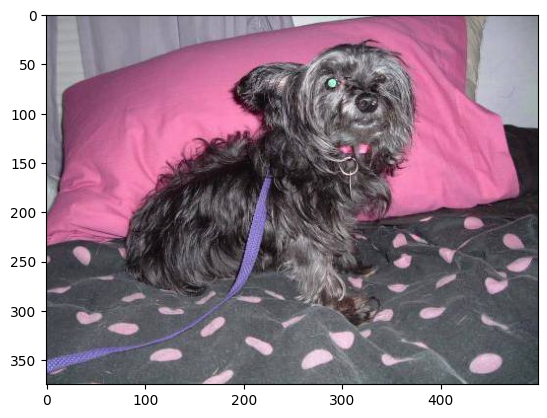

In [38]:
img = mpimg.imread('/content/dogs_vs_cats/train/train/dog.0.jpg')
plt.imshow(img)

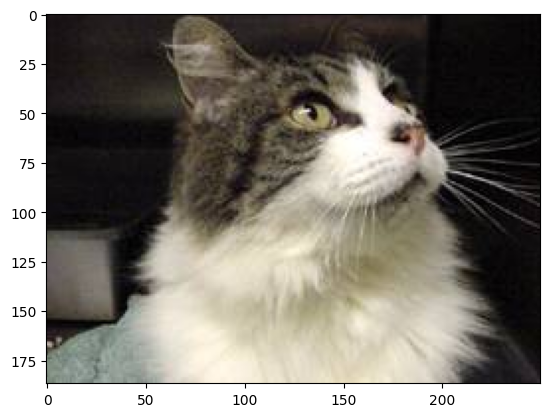

In [39]:
img = mpimg.imread('/content/dogs_vs_cats/train/train/cat.1383.jpg')
plt.imshow(img)

RESIZING  THE IMAGES

In [40]:
#creating a directory for resized image
os.mkdir('/content/image resized')

In [41]:


original_path = '/content/dogs_vs_cats/train/train'
resized_path = '/content/image resized'

os.makedirs(resized_path, exist_ok=True)

print("Original folder:", original_path)
print("Resized folder:", resized_path)

Original folder: /content/dogs_vs_cats/train/train
Resized folder: /content/image resized


In [44]:
# Creating a directory for resized images
import os
os.makedirs('/content/image resized', exist_ok=True)

original_folder = '/content/dogs_vs_cats/train/train/'
resized_folder = '/content/image resized/'

for i in range(2000):

    filename = os.listdir(original_folder)[i]

    img_path = original_folder + filename

    img = Image.open(img_path)

    img = img.resize((224, 224))

    img = img.convert('RGB')

    newImgPath = resized_folder + filename

    img.save(newImgPath)

resized image

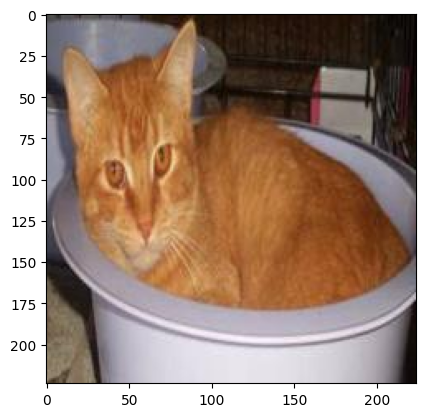

In [49]:
img = mpimg.imread('/content/image resized/' + os.listdir(resized_folder)[2])

plt.imshow(img)

**create labels for resized images of dogs and cats bold text**

cat--->0
dog--->1

In [50]:
labels = []

for i in range(2000):
    filename = os.listdir(resized_folder)[i]

    if filename.startswith('cat'):
        labels.append(0)
    else:
        labels.append(1)

print(labels[:10])
print("Total labels:", len(labels))

[1, 0, 0, 0, 0, 1, 0, 0, 0, 0]
Total labels: 2000


counting the images of dogs and cats out of 2000 images

In [51]:
cat_count = 0
dog_count = 0

for i in range(2000):
    filename = os.listdir(resized_folder)[i]

    if filename.startswith('cat'):
        cat_count += 1
    elif filename.startswith('dog'):
        dog_count += 1

print("Number of cats:", cat_count)
print("Number of dogs:", dog_count)
print("Total images:", cat_count + dog_count)

Number of cats: 1029
Number of dogs: 971
Total images: 2000


In [54]:
import cv2
import glob

image_directory = '/content/image resized/'
image_extension = ['png', 'jpg']

files = []

[files.extend(glob.glob(image_directory + '*.' + e)) for e in image_extension]

dog_cat_images = np.asarray([cv2.imread(file) for file in files])

In [55]:
print(dog_cat_images)

[[[[ 68 120 143]
   [ 74 124 146]
   [ 83 127 150]
   ...
   [ 11  10  19]
   [ 11   8  17]
   [  9   6  15]]

  [[ 75 124 146]
   [ 80 127 148]
   [ 85 128 149]
   ...
   [ 10   9  18]
   [ 10   7  16]
   [  9   6  15]]

  [[ 85 128 147]
   [ 88 131 148]
   [ 93 131 149]
   ...
   [  8   7  16]
   [ 10   7  16]
   [  9   6  15]]

  ...

  [[ 83  83  97]
   [ 86  86 100]
   [ 85  85  99]
   ...
   [194 184 197]
   [190 180 193]
   [187 177 190]]

  [[ 83  80  95]
   [ 89  86 101]
   [ 89  89 103]
   ...
   [197 187 200]
   [193 183 196]
   [189 179 192]]

  [[ 81  78  93]
   [ 90  87 102]
   [ 93  93 107]
   ...
   [200 190 203]
   [195 185 198]
   [191 181 194]]]


 [[[255 255 255]
   [255 255 255]
   [255 255 255]
   ...
   [255 255 255]
   [255 255 255]
   [255 255 255]]

  [[255 255 255]
   [255 255 255]
   [255 255 255]
   ...
   [255 255 255]
   [255 255 255]
   [255 255 255]]

  [[255 255 255]
   [255 255 255]
   [255 255 255]
   ...
   [255 255 255]
   [255 255 255]
   [255 255

In [56]:
print(dog_cat_images.shape)

(2000, 224, 224, 3)


In [57]:
X = dog_cat_images
y = np.asarray(labels)

train test split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [59]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1600, 224, 224, 3)
(400, 224, 224, 3)
(1600,)
(400,)


scaling the data

In [60]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [61]:
print(X_train)

[[[[0.43529412 0.58823529 0.7372549 ]
   [0.43529412 0.58823529 0.7372549 ]
   [0.43137255 0.58431373 0.73333333]
   ...
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]]

  [[0.42745098 0.58039216 0.72941176]
   [0.42352941 0.57647059 0.7254902 ]
   [0.42352941 0.57647059 0.7254902 ]
   ...
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]]

  [[0.41568627 0.56862745 0.71764706]
   [0.41176471 0.56470588 0.71372549]
   [0.40784314 0.56078431 0.70980392]
   ...
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]
   [0.40784314 0.55686275 0.55686275]]

  ...

  [[0.33333333 0.5372549  0.65490196]
   [0.33333333 0.5372549  0.65490196]
   [0.3372549  0.54117647 0.65882353]
   ...
   [0.45490196 0.61960784 0.73333333]
   [0.45490196 0.61960784 0.73333333]
   [0.45490196 0.61960784 0.73333333]]

  [[0.3254902  0.5372549  0.65490196]
   [0.3

In [62]:
import tensorflow as tf
import tensorflow_hub as hub

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [63]:
mobilenet_model='https://www.tensorflow.org/s/results?q=tf2-preview%2Fmobilenet'
pretrained_model=tf.keras.applications.MobileNetV2(input_shape=(224,224,3),include_top=False,weights='imagenet',pooling='avg')
pretrained_model.trainable=False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [65]:
num_of_classes = 2

model = tf.keras.Sequential()

model.add(pretrained_model)
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(num_of_classes, activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['acc']
)
model.summary()




Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [66]:
model.fit(X_train, y_train, epochs=5, batch_size=32)

Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - acc: 0.8637 - loss: 0.3196
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - acc: 0.9481 - loss: 0.1391
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - acc: 0.9663 - loss: 0.1023
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - acc: 0.9656 - loss: 0.0993
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - acc: 0.9688 - loss: 0.0852


In [68]:
score,acc=model.evaluate(X_test,y_test)
print('Test loss',score)
print('Test accuracy',acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - acc: 0.9625 - loss: 0.0881
Test loss 0.08813639730215073
Test accuracy 0.9624999761581421


**prectictive system**

Path of the image to be predicted: /content/dog.img


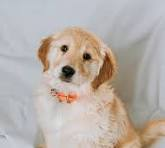

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1
It is a Dog


In [70]:
input_image_path = input('Path of the image to be predicted: ')

input_image = cv2.imread(input_image_path)

cv2_imshow(input_image)

input_image_resize = cv2.resize(input_image, (224, 224))

input_image_scaled = input_image_resize / 255

image_reshaped = np.reshape(input_image_scaled, [1, 224, 224, 3])

input_prediction = model.predict(image_reshaped)

input_pred_label = np.argmax(input_prediction)

print(input_pred_label)
if input_pred_label == 1:
    print("It is a Dog")
else:
    print("It is a Cat")